In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal
import numpy as np

In [2]:
df=pd.read_csv('data.csv')
df.head()

,time,u,y
0,0.000758,73.051979,0.093873
1,0.010457,59.356608,1.213926
2,0.020310,77.842171,2.302655
3,0.030256,82.031419,3.413871
4,0.040137,83.181970,4.478697


In [3]:
t=df.time
u=df.u
y=df.y
N_total=len(u)

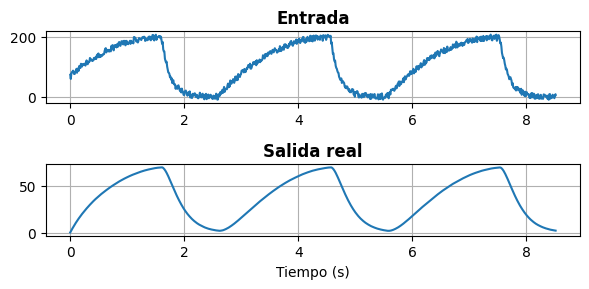

In [4]:
plt.figure(figsize=(6,3))

plt.subplot(2,1,1)
plt.plot(t,u)
plt.grid(True)
plt.title('Entrada',fontweight='bold')

plt.subplot(2,1,2)
plt.plot(t,y)
plt.grid(True)
plt.title('Salida real',fontweight='bold')
plt.xlabel('Tiempo (s)')

plt.tight_layout()
plt.show()

In [5]:
def identificar_por_desconvolucion(u, y, N):
    pad_length = round(N / 5)
    ypad = np.concatenate([y[:N], np.zeros(pad_length)])
    h, remainder = signal.deconvolve(ypad, u[:N])
    return h

def identificar_por_LSE(t, u, y, N, p):
    # Construir la matriz U con desplazamientos adecuados
    U = np.zeros((N - p + 1, p))
    for i in range(p):
        U[:, i] = u[p - i - 1:N - i]

    y_lse = y[p - 1:N]  # Alineado con U

    # Resolver sistema normal sin escalar por T
    A = U.T @ U
    b = U.T @ y_lse
    h = np.linalg.solve(A, b)

    return h

def calcular_PE(y_real, y_pred):
    eps = 1e-10  # evitar división por cero
    return np.mean(np.abs((y_real - y_pred) / (y_real + eps)))  # norma L1 normalizada


In [6]:
# Configuración de los casos: (metodo, N_fraccion, nombre)
casos = [
    ('desconvolucion', 1/3, 'YD1'),
    ('desconvolucion', 1/5, 'YD2'),
    ('desconvolucion', 1/10, 'YD3'),
    ('lse', 1/3, 'YL1'),
    ('lse', 1/5, 'YL2'),
    ('lse', 1/10, 'YL3'),
]

# Guardar resultados
resultados = []

for metodo, fraccion, nombre in casos:
    N = int(N_total * fraccion)
    if metodo == 'desconvolucion':
        h = identificar_por_desconvolucion(u, y, N)
    else:
        p = round(N / 5)
        h = identificar_por_LSE(t, u, y, N, p)

    y_pred = signal.convolve(u[:N], h)[:N]
    y_real = y[:N]
    PE = calcular_PE(y_real, y_pred)

    resultados.append({
        'nombre': nombre,
        'y_real': y_real,
        'y_pred': y_pred,
        'PE': PE,
        'h':h
    })

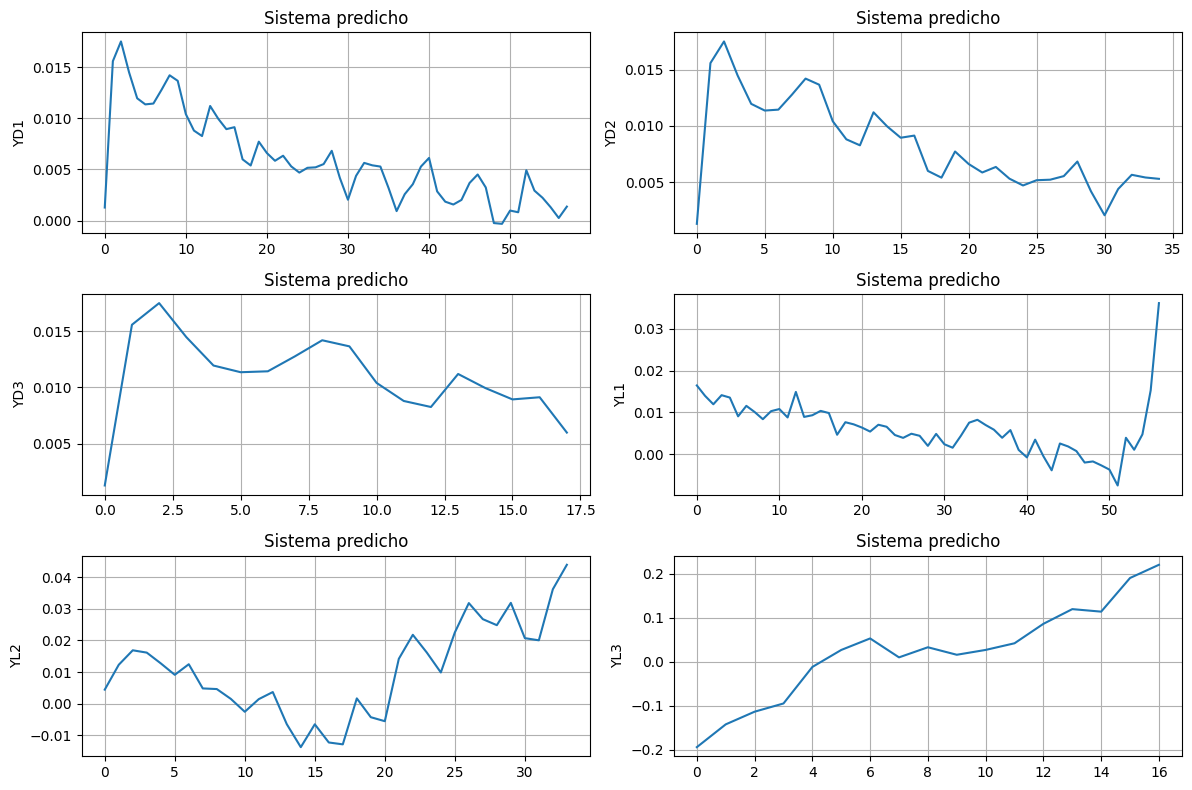

In [7]:
plt.figure(figsize=(12, 8))
for i, res in enumerate(resultados):
    plt.subplot(3, 2, i + 1)
    plt.plot(res['h'])
    plt.title('Sistema predicho')
    plt.ylabel(res['nombre'])
    plt.grid(True)
plt.tight_layout()
plt.show()


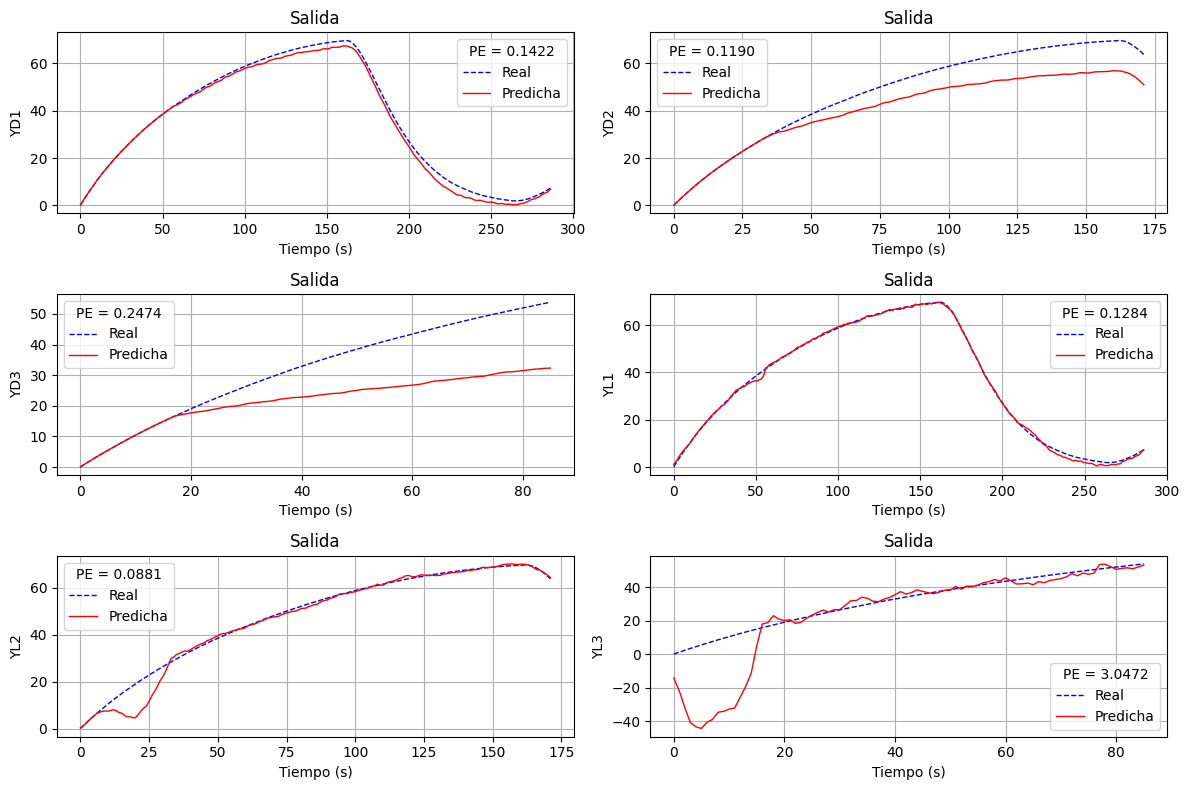

In [8]:
plt.figure(figsize=(12, 8))
for i, res in enumerate(resultados):
    plt.subplot(3, 2, i + 1)
    plt.plot(res['y_real'], label='Real', linewidth=1, linestyle='--',color='blue')
    plt.plot(res['y_pred'], label='Predicha', linewidth=1, color='red')
    plt.title('Salida')
    plt.xlabel('Tiempo (s)')
    plt.ylabel(res['nombre'])
    plt.legend(title=f'PE = {res["PE"]:.4f}')
    plt.grid(True)

plt.tight_layout()
plt.show()